# Photon-number model: grouping, fitting and the Poisson test

This notebook walks through the photon-number analysis behind Figs. 6 and 7 (and Supplementary Note 6).
The computation lives in [`analysis/build_pnr_model.py`](../analysis/build_pnr_model.py) (grouping the GMM
components into photon numbers) and [`analysis/pnr_refit.py`](../analysis/pnr_refit.py) (fitting group weights
and a timing offset to every attenuation); [`analysis/make_fig_pnr.py`](../analysis/make_fig_pnr.py) draws the
paper figures.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
import orjson
from analysis.datasets import get, decode_path
from analysis.build_pnr_model import filter_components, affinity, stable_communities
from analysis.pnr_refit import load_groups, load_events, fit_weights_and_shift, init_shift_grid, flatten, group_loglik, poisson_pmf

DATASET = "20"
cfg = get(DATASET)
d = orjson.loads(open(decode_path(cfg, cfg["model_db"]), "rb").read())
g = d["gm_data"]["gm_list"][15]          # the 35-component preamble fit used for the 20 GHz model
means, covs, weights = (np.asarray(g[k], float) for k in ("means", "covariances", "weights"))
means, covs, weights = filter_components(means, covs, weights, 1000.0)
print(f"{cfg['model_db']} dB preamble: 35 components -> {len(weights)} after removing far-field and degenerate ones")

24 dB preamble: 35 components -> 30 after removing far-field and degenerate ones


## 1. Which components belong together?

The symmetric KL divergence between every pair of components defines a graph; components describing the
same photon-number cluster are strongly connected.

Text(0, 0.5, 'component')

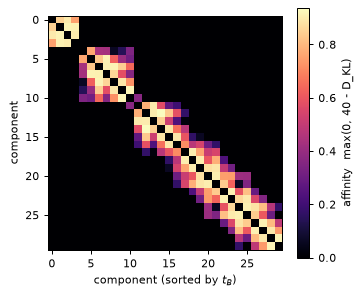

In [2]:
A = affinity(means, covs)
order = np.argsort(-means[:, 1])          # sort by t_B: 1-photon components first
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(A[np.ix_(order, order)], cmap="magma"); fig.colorbar(im, ax=ax, label="affinity  max(0, 40 - D_KL)")
ax.set_xlabel("component (sorted by $t_B$)"); ax.set_ylabel("component")

## 2. Louvain communities, made reproducible

Louvain community detection is randomized, and its resolution parameter sets how many groups come out. The
2023 notebook ran it once without a seed. Here we count, for each resolution, how often 50 seeds give each
number of groups; the model uses the lowest resolution that yields five groups (1, 2, 3, 4, 5+ photons) and the
most frequent partition there.

In [3]:
import networkx as nx
G = nx.from_numpy_array(A)
res_grid = np.arange(0.5, 1.21, 0.1)
counts = {r_: np.bincount([len(nx.community.louvain_communities(G, resolution=r_, seed=s)) for s in range(50)], minlength=9)
          for r_ in res_grid}
print("resolution  fraction of seeds giving 3..8 groups")
for r_, c_ in counts.items():
    print(f"   {r_:.1f}     " + "  ".join(f"{x/50:.2f}" for x in c_[3:9]))
parts, res, freq = stable_communities(A, 5, np.arange(0.5, 2.01, 0.05))
print(f"\nchosen: resolution {res:.2f}, partition found in {100*freq:.0f}% of seeds")

resolution  fraction of seeds giving 3..8 groups
   0.5     0.00  1.00  0.00  0.00  0.00  0.00
   0.6     0.00  1.00  0.00  0.00  0.00  0.00
   0.7     0.00  1.00  0.00  0.00  0.00  0.00
   0.8     0.00  0.10  0.90  0.00  0.00  0.00
   0.9     0.00  0.04  0.96  0.00  0.00  0.00
   1.0     0.00  0.02  0.98  0.00  0.00  0.00
   1.1     0.00  0.00  1.00  0.00  0.00  0.00
   1.2     0.00  0.00  1.00  0.00  0.00  0.00

chosen: resolution 0.80, partition found in 90% of seeds


## 3. Fitting the model to every attenuation

As in the 2023 analysis, the group weights at each attenuation are Poisson(mu, j) at the measured mean
photon number. What is fitted (expectation-maximization) is the model's timing offset, applied equally to
$t_A$ and $t_B$; this replaces the 2023 offset vectors, which were hand-adjusted at 16-20 dB.

16 dB: 2023 vector (-466.0, -484.0) ps, fitted (-494.1, -494.1) ps
18 dB: 2023 vector (+40.0, +32.0) ps, fitted (+18.3, +18.3) ps
20 dB: 2023 vector (+37.0, +34.0) ps, fitted (+19.8, +19.8) ps
22 dB: 2023 vector (+18.6, +19.6) ps, fitted (+15.5, +15.5) ps


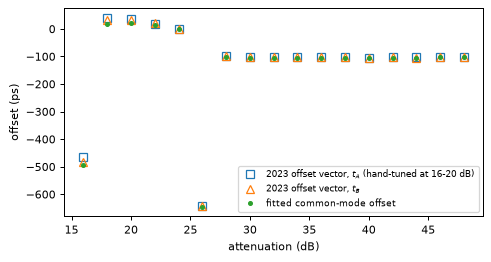

In [4]:
groups = load_groups(cfg["model"]); J = len(groups)
refit = json.loads(open(cfg["refit"]).read())
dbs = sorted(int(float(k)) for k in refit)
legacy = {db: json.loads(open(cfg["inter"] / f"offset_correction_{db}.json").read())["correction_vector"] for db in dbs}
fit = {db: refit[f"{db:.1f}"]["shift"] for db in dbs}
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(dbs, [-legacy[db][0] for db in dbs], "s", mfc="none", label="2023 offset vector, $t_A$ (hand-tuned at 16-20 dB)")
ax.plot(dbs, [-legacy[db][1] for db in dbs], "^", mfc="none", label="2023 offset vector, $t_B$")
ax.plot(dbs, [fit[db][0] for db in dbs], "o", ms=3, label="fitted common-mode offset")
ax.set_xlabel("attenuation (dB)"); ax.set_ylabel("offset (ps)"); ax.legend(fontsize=7)
for db in (16, 18, 20, 22):
    print(f"{db} dB: 2023 vector ({-legacy[db][0]:+.1f}, {-legacy[db][1]:+.1f}) ps, fitted ({fit[db][0]:+.1f}, {fit[db][1]:+.1f}) ps")

## 4. Robustness check: free group weights

`pnr_refit.py` also fits the five group weights freely (no Poisson prior) and attributes the detections
with those. The two attributions agree closely: the photon-number clusters are separated well enough that
the weights only matter for the few detections between the 4 and 5+ groups.

In [5]:
print(" dB    mu     | 1..5+ photons, Poisson(mu) weights (paper)   | free weights")
for db in (36, 30, 26, 24, 22):
    r_ = refit[f"{db:.1f}"]
    pois = np.array(r_["counts"]); free = np.array(r_["counts_free_weights"])
    print(f"{db}   {r_['mu']:6.3f}  | " + " ".join(f"{x:.3f}" for x in pois/pois.sum())
          + "   | " + " ".join(f"{x:.3f}" for x in free/free.sum()))

 dB    mu     | 1..5+ photons, Poisson(mu) weights (paper)   | free weights
36    0.227  | 0.888 0.104 0.008 0.000 0.000   | 0.888 0.103 0.008 0.000 0.000
30    0.913  | 0.615 0.278 0.085 0.019 0.003   | 0.615 0.279 0.085 0.019 0.003
26    2.267  | 0.254 0.302 0.229 0.137 0.078   | 0.254 0.302 0.229 0.140 0.076
24    3.477  | 0.102 0.192 0.222 0.212 0.273   | 0.102 0.192 0.220 0.216 0.270
22    5.441  | 0.022 0.060 0.100 0.170 0.649   | 0.022 0.060 0.099 0.178 0.642


## 5. An independent estimate of mu

The freely fitted weights give a second estimate of mu (a zero-truncated Poisson fit to them) that does
not use the vacuum fraction. It agrees with the vacuum-fraction estimate up to mu of about 5, above which the
5+ group no longer describes the detector response.

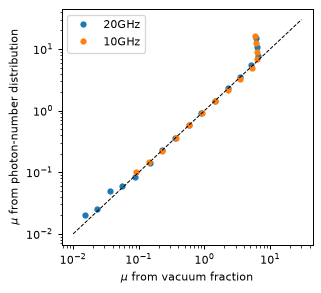

In [6]:
fig, ax = plt.subplots(figsize=(3.6, 3.4))
for key, color in [("20", "C0"), ("10", "C1")]:
    rf = json.loads(open(get(key)["refit"]).read())
    mv = np.array([v["mu_vacuum"] for v in rf.values()]); mp = np.array([v["mu_from_free_weights"] for v in rf.values()])
    ax.loglog(mv, mp, "o", ms=4, color=color, label=get(key)["tag"])
ax.plot([0.01, 30], [0.01, 30], "k--", lw=0.8)
ax.set_xlabel(r"$\mu$ from vacuum fraction"); ax.set_ylabel(r"$\mu$ from photon-number distribution"); ax.legend()